# Red Cedar — Training in Depth

A closer look at training, beyond the quick start:
1. Training loss and accuracy
2. Layers and layer chaining
3. Test accuracy over the course of training
4. Results per class and per layer
5. Choosing the train and test data
6. Finding and reusing trained models
7. Checking on and stopping a running job

Run the setup cell first; after that, each section can be run on its own.

In [1]:
import redcedar
import matplotlib.pyplot as plt

# Connect to the server
# Reads REDCEDAR_URL and REDCEDAR_API_KEY from environment, or pass explicitly:
# client = redcedar.connect(url="http://127.0.0.1:8002", api_key="your-key")
# With the Red Cedar source installed (pip install -e), local mode calls it directly:
# client = redcedar.connect(local=True)
client = redcedar.connect()
print(f"Red Cedar SDK v{redcedar.__version__}")
status = client.status()
print(f"Server: {client.url or 'local mode, in this process'} (version {status['server_version'] or 'unknown'}, ok={status['ok']})")

dataset = "wdbc"
base = {"num_qubits": 6, "seed": 123}

Red Cedar SDK v0.93.0
Server: http://127.0.0.1:8002 (version 0.92-18-g1706a0dc-dirty, ok=True)


## 1. Training loss and accuracy

While a model trains, Red Cedar measures its loss and accuracy on the training rows after every parameter update, in each layer. These measurements come back with the result, in `result["history"]`, so you can see how the training progressed.

- **Training loss** says how far the model's answers are from the right ones. For each row the model gives a probability to every class; the loss is built from 1 minus the probability of the correct class, averaged over the training rows. It goes down as the model becomes more sure of the right answers.
- **Training accuracy** is the share of training rows whose correct class is the one the model finds most likely.

The test results printed below are the same two measures on the rows held back from training, which the model never trains on. The [User Guide](https://coherent-computing.github.io/redcedar/user_guide/#training-loss-and-accuracy) has the details.

The plots show both, one curve per layer; the dashed line marks where a new layer starts. A falling loss and a rising accuracy show the model is learning, and a curve that levels off means that layer has gone as far as it can.

Layer 1: test accuracy 75.4%, test loss 0.5195
Layer 2: test accuracy 79.8%, test loss 0.5529


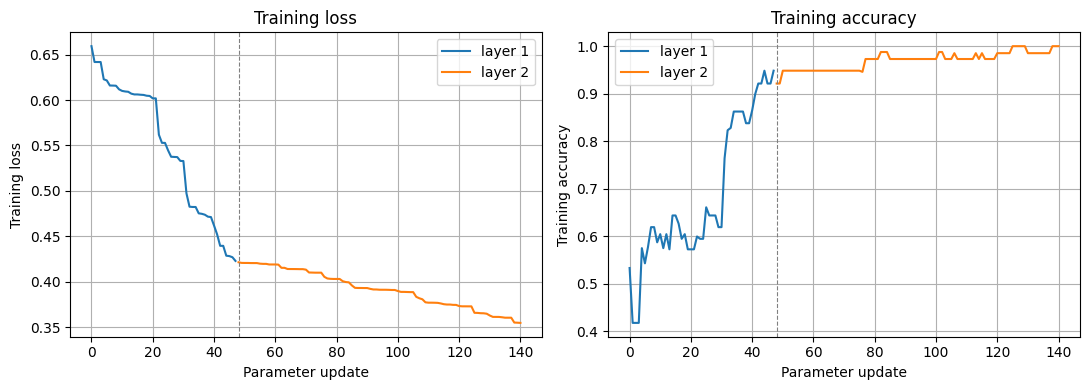

In [2]:
result = client.training.run(dataset, settings=dict(base, min_layers=1, max_layers=2))
for layer, v in result["validation"].items():
    print(f"Layer {layer}: test accuracy {v['test_accuracy']:.1%}, test loss {v['test_loss']:.4f}")

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
start = 0
for layer, points in result["history"].items():
    steps = range(start, start + len(points))
    ax_loss.plot(steps, [p["train_loss"] for p in points], label=f"layer {layer}")
    ax_acc.plot(steps, [p["train_accuracy"] for p in points], label=f"layer {layer}")
    if start:
        ax_loss.axvline(start, color="gray", ls="--", lw=0.8)
        ax_acc.axvline(start, color="gray", ls="--", lw=0.8)
    start += len(points)

ax_loss.set(xlabel="Parameter update", ylabel="Training loss", title="Training loss")
ax_acc.set(xlabel="Parameter update", ylabel="Training accuracy", title="Training accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Layers and layer chaining

A training run covers the layers from `min_layers` to `max_layers`. Each layer is a separate model with one more layer of operators than the one before.

With `chain_layers` on (the default), each layer starts from the parameters the previous layer found, with its new operators starting at zero, so it begins exactly where the smaller model left off. With `chain_layers` off, each layer starts from scratch. Below, the same three layers are trained both ways (this takes a few minutes), and the plots show the training loss (section 1).

chain_layers=True:
  layer 1: test accuracy 75.4%, test loss 0.5195
  layer 2: test accuracy 79.8%, test loss 0.5529
  layer 3: test accuracy 79.8%, test loss 0.6852
chain_layers=False:
  layer 1: test accuracy 75.4%, test loss 0.5195
  layer 2: test accuracy 78.1%, test loss 0.5373
  layer 3: test accuracy 79.8%, test loss 0.6109


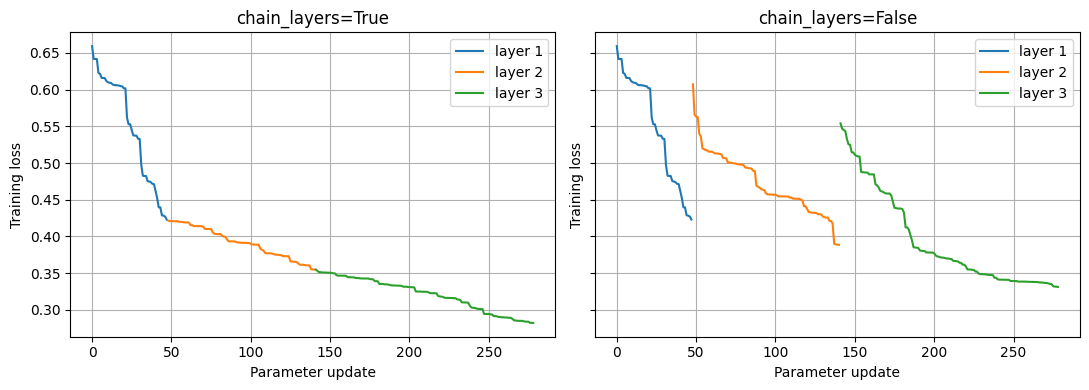

In [3]:
runs = {}
for chain in [True, False]:
    runs[chain] = client.training.run(dataset, settings=dict(base, min_layers=1, max_layers=3, chain_layers=chain))
    print(f"chain_layers={chain}:")
    for layer, v in runs[chain]["validation"].items():
        print(f"  layer {layer}: test accuracy {v['test_accuracy']:.1%}, test loss {v['test_loss']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, chain in zip(axes, [True, False]):
    start = 0
    for layer, points in runs[chain]["history"].items():
        ax.plot(range(start, start + len(points)), [p["train_loss"] for p in points], label=f"layer {layer}")
        start += len(points)
    ax.set(title=f"chain_layers={chain}", xlabel="Parameter update", ylabel="Training loss")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Test accuracy over the course of training

The server saves the parameters after every update. `training.analyze()` replays them on the test data, so you can compare test accuracy with training accuracy as training goes on, and see whether the model starts to overfit. `layer` picks the layer (default: the last); here it's layer 1, where most of the learning happens.

Layer 1: 48 checkpoints, final test accuracy 75.4%


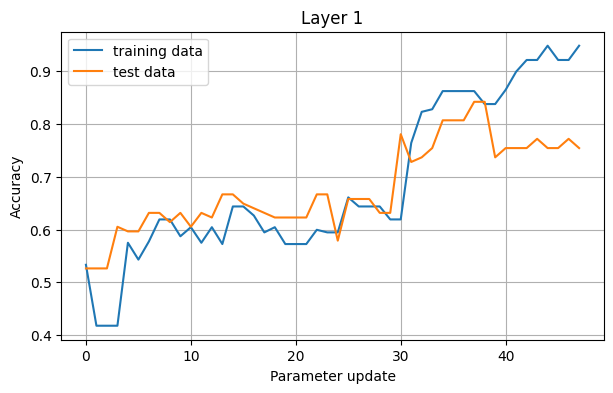

In [4]:
train_id = runs[True]["train_id"]
replay = client.training.analyze(train_id, layer=1)
train_curve = runs[True]["history"][1]

print(f"Layer {replay['layer']}: {replay['num_checkpoints']} checkpoints, "
      f"final test accuracy {replay['final_accuracy']:.1%}")

plt.figure(figsize=(7, 4))
plt.plot([p["train_accuracy"] for p in train_curve], label="training data")
plt.plot(replay["accuracy_history"], label="test data")
plt.xlabel("Parameter update")
plt.ylabel("Accuracy")
plt.title("Layer 1")
plt.legend()
plt.grid(True)
plt.show()

## 4. Results per class and per layer

The validation results for each layer include the test accuracy for each class. `training.evaluate()` runs a trained model again on the rows the server set aside from the training data (by default with its last layer, or any single layer). For predictions on new rows, use `inference.run()` with a file, as in `01_quick_start.ipynb`.

In [5]:
for layer, v in runs[True]["validation"].items():
    per_class = ", ".join(f"class {c}: {a:.1%}" for c, a in v["test_accuracy_per_class"].items())
    print(f"Layer {layer}: {per_class}")

layer_1 = client.training.evaluate(train_id, layer=1)
print(f"\nInference on layer 1: accuracy {layer_1['overall_accuracy']:.1%} on {layer_1['test_samples']} samples")

evaluation = client.training.evaluate(train_id)
print(f"\nInference on the last layer: accuracy {evaluation['overall_accuracy']:.1%} on {evaluation['test_samples']} samples")
for cls in evaluation["per_class"]:
    print(f"  Class {cls['class']}: accuracy {cls['accuracy']:.1%} ({cls['samples']} samples)")

Layer 1: class 1: 63.9%, class 2: 95.2%
Layer 2: class 1: 80.6%, class 2: 78.6%
Layer 3: class 1: 80.6%, class 2: 78.6%

Inference on layer 1: accuracy 75.4% on 114 samples

Inference on the last layer: accuracy 79.8% on 114 samples
  Class 1: accuracy 80.6% (72 samples)
  Class 2: accuracy 78.6% (42 samples)


## 5. Choosing the train and test data

`train_size` and `test_size` set how much data is used, as a fraction of the dataset or a number of samples. `class_range` picks a subset of classes in a multi-class dataset (catalog datasets only). Smaller training sets train faster; larger test sets give more reliable accuracy figures.

In [6]:
small = client.training.run(dataset, settings=dict(base, max_layers=1), train_size=100, test_size=200)
check = client.training.evaluate(small["train_id"])
print(f"Trained on 100 samples: test accuracy {check['overall_accuracy']:.1%} on {check['test_samples']} test samples")

Trained on 100 samples: test accuracy 83.0% on 200 test samples


## 6. Finding and reusing trained models

Trained models stay on the server, so a `train_id` can be used later, from another notebook or session, for inference, explainable AI or the replay. `inference.models()` lists the most recent models with the settings they were trained with.

In [7]:
# The most recent models trained on this dataset (the list has every model on the server)
models = [m for m in client.inference.models()["models"] if m["dataset_name"] == dataset]
for m in models[:5]:
    p = m["training_params"]
    print(f"{m['train_id'][:8]}  {m['dataset']:18s} qubits={m['num_qubits']}  layers={m['layers']}  seed={p.get('seed')}")

62d10c07  WDBC (Breast Cancer) qubits=6  layers=[1]  seed=123
978e393d  WDBC (Breast Cancer) qubits=6  layers=[1, 2, 3]  seed=123
ddccdf6c  WDBC (Breast Cancer) qubits=6  layers=[1, 2, 3]  seed=123
6f15864c  WDBC (Breast Cancer) qubits=6  layers=[1, 2]  seed=123


## 7. Checking on and stopping a running job

`training.run()` waits until training ends. To keep working while a model trains, start it in a background thread; `training.status()` reports on it and `training.stop()` stops it. Layers that finished are kept. The server runs one job at a time, so a job submitted while another runs waits in the queue and starts when the first one ends.

In [8]:
import threading, time

job = {}
def train_in_background():
    try:
        job["result"] = client.training.run(dataset, settings={"num_qubits": 6, "min_layers": 1, "max_layers": 3})
    except RuntimeError as e:
        job["error"] = str(e)

thread = threading.Thread(target=train_in_background)
thread.start()

# Wait until the job is running (the SDK keeps the ID of the job it submitted last)
time.sleep(2)
while True:
    try:
        status = client.training.status(client._last_job_id)
        if status["status"] == "running":
            break
    except Exception:
        pass   # not started yet
    time.sleep(1)
print("Status:", status["status"], f"({status['progress']}%)")

time.sleep(5)
print(client.training.stop(client._last_job_id)["message"])
thread.join()
print("training.run() ended with:", job)
print("Status:", client.training.status(client._last_job_id)["status"])

Status: running (5%)
Stop requested for bc10335e-3e01-4fdc-b4f9-cb0c31b5a51c.
training.run() ended with: {'error': 'Training stopped'}
Status: stopped
